# Navigating the design parameter sea for rare-event sampling algorithms

#### Author: Noé Blassel
#### "Learning the Dynamics of Biological Macromolecules" research school, Cargèse, November 2026

This practical session is not about coding algorithms, but rather experimenting with their hyperparameters and their impact on the performance, in some dynamical rare-event sampling methods. While every choice of parameter will generally give some numerical result, each choice may impact both the correctness and efficiency of predictions.

I imagine the situation is something like a serene sea of valid parameters, but with reefs and sharp cliffs. Beware of the rocks !

<div style="text-align:center">
<img src="./figures/cargese.jpg" width="500"/>

<i>Cargèse, Corsica</i>
</div>



The two methods we will look at today are the **parallel replica** algorithm (ParRep, [A. Voter 1998](https://doi.org/10.1103/PhysRevB.57.R13985)) and the **adaptive multilevel
splitting** method (AMS, [F. Cérou and A. Guyader, 2007](https://doi.org/10.1080/07362990601139628)).

Before running this notebook, run the installation script using `./setup.sh`. On Linux and macOS, this will install [Julia](https://julialang.org/) and the necessary packages inside this folder, and a Jupyter kernel. It may take a while, so don't wait for the session to start ! On Windows, you need to run the script and notebook inside [WSL](https://learn.microsoft.com/en-us/windows/wsl/install). Everything can be uninstalled after the session by running `./uninstall.sh`.

It is also possible to run this notebook in Colab (link TODO). This is however not recommended, as you will be limited to using two threads.

First, we load the code and check that multithreading is enabled (this will be important for parallel replica).

In [ ]:
using RareEventLab, Plots
println("Running with ", Threads.nthreads(), " threads")
mkpath("./plots/")

## Physical system

We want to sample trajectories of the overdamped Langevin dynamics
$$\mathrm{d}X_t = -\nabla V(X_t)\,\mathrm{d}t + \sqrt{2/\beta}\,\mathrm{d}W_t$$
where $V:{\mathcal X}\to {\mathbb R}$ is a three-well potential energy function we call the "entropic switch potential" (see the plot below).
The inverse temperature will be fixed throughout at $\beta = 1/(kT)= 2.5$.

This dynamics has an explicit invariant probability distribution on $\mathcal X= \mathbb R^2$
$$
\mu({\rm d} x) = \frac1Z{\rm e}^{-\beta V(x)}\,{\rm d}x.
$$

For discretization, we use a Euler–Maruyama scheme with the time step $\Delta t = 5\cdot 10^{-3}$.

The two deep minima (the left and right ones) are surrounded by the **physical milestones** $A$ and $B$ (the circles in the plot below).

Trajectories from $A$ to $B$ have **two available pathways**: over the
top state (low energy cost, high entropy cost), or through the bottom (high energy, low entropy). The temperature
is tuned so that both pathways are likely.

Use the following cell to make the plot, and visualize a trajectory of the dynamics. Unless you are **very** lucky, the trajectory stays around one minimum: the dynamics are **metastable**.

In [ ]:
p = show_potential()
path = sample_trajectory(10.0)
plot!(p, first.(path), last.(path); c = :red, lw = 0.2, alpha = 1, label = "trajectory, T = 10")

## Reactive observables

Let $\tau_0^A < \tau_0^B < \tau_1^A<\dots$ be the *reactive times*, defined by hitting times of $\partial A$ or $\partial B$ coming from $B$ or $A$ respectively.
In the picture below, think of $\tau_0^A$ as occurring in the middle of a very long equilibrium trajectory.

![Reactive entrance times in A and B](figures/fig1.png)

*From [M. Baudel, A. Guyader and T. Lelièvre, 2023](https://doi.org/10.1016/j.spa.2022.10.014).*



Here are some typical dynamical properties we care about
- **Equilibrium reactive entry distributions**. The distribution $\nu_A$ of $X_{\tau_{0}^A}\in\partial A$, and $\nu_B$ of $X_{\tau_0^B}$ at equilibrium.
- **Equilibrium reaction rates**. $k_{AB} = 1/{\mathbb E}_{\nu_A}[\tau_0^B-\tau_0^A]$. In our system $k_{BA}=k_{AB}$ by symmetry.
- **Equilibrium distribution of reactive paths**, or at least of which pathway they took (the reactive mechanism).

Because of metastability, measuring these properties by brute-force simulation require **long trajectories**. Reference values in the cell below were precomputed using a very long simulation.

In [ ]:
ref = reference()
println("k_AB (reference)            = ", round(ref.k_AB; sigdigits = 3), " ± ", round(2ref.k_AB_se; sigdigits = 2)) # ± 2 standard errors
println("P(top pathway) (reference)     = ", round(ref.p_top; digits = 3), " ± ", round(2ref.p_top_se; sigdigits = 2))
println("mean A → B time             = ", round(1 / ref.k_AB; digits = 1), " = ", round(Int, 1 / (ref.k_AB * Δt)), " integration steps")

> What is the order of the number of force evaluations you would need to observe 1000 transitions?
> How long would that take using 100 cores, if you could divide one trajectory between them ?

---
## 1. The parallel replica algorithm

We look at the version from [N.B., T. Lelièvre, G. Stoltz, 2026, Appendix B](https://doi.org/10.1142/S0218202526500405), which uses core-sets, deterministic decorrelation times and rejection sampling. Other variants exist, e.g. [A. Binder, T. Lelièvre, G. Simpson, 2015](https://doi.org/10.1016/j.jcp.2015.01.002)


### Algorithm
Fix a collection of **metastable states**. Each state is a subset of configuration space $\Omega \subset \mathcal X$, containing a **core-set** $C \subseteq \Omega$ (these are different in general from the milestones $A$ and $B$). For each state, we define a **decorrelation time** $t_{\rm corr}(\Omega)>0$.

- **A) Initialization.** Simulate a *reference walker* $X$ sequentially until it enters a core-set $C\subset\Omega$.
- **B) Decorrelation.** For a time $t_{\rm corr}(\Omega)$, evolve in parallel $N$ independent *replicas* of $X$, branching from the reference walker.
  - **B1)** If the reference walker (replica 1) leaves $\Omega$ during this time, go back to **A)**, and advance the clock by the time the reference walker spent in **B)**.
  - **B2)** If not, keep only the $N_{\rm eff}\leq N$ replicas that remained inside $\Omega$ for the whole of step **B)**, and advance the clock by $t_{\rm corr}(\Omega)$.
- **C) Parallel exit.**  Simulate the $N_{\rm eff}$ surviving replicas from **B)** independently in parallel.
  - **C1)** When the first replica exits after a time $T_{\rm par}$ in step **C)**, advance the physical simulation clock by $N_{\rm eff}T_{\rm par}$ steps. In discrete time, the implementation uses the unbiased increment $N_{\rm eff}(T_{\rm par}-1)+K$ steps, where $K$ is the index of the first replica to exit.
  - **C2)** Start again from **A)** with the first exiting replica as the new reference walker.

### Why does this work ?
At the end of step **B)**, and **if $t_{\rm corr}(\Omega)$ is large enough**, the surviving replicas are approximately independent and distributed according to the **quasi-stationary distribution (QSD)** $\nu_\Omega$ in $\Omega$ (they are *i.i.d.*). Then:

- Starting from the QSD, the exit time $\tau^\Omega$ from $\Omega$ is **exponentially distributed and independent from the exit point**
$$
{\mathbb P}_{\nu_\Omega}\left(\tau^\Omega > t, X_{\tau^\Omega}\in \Gamma\right) = {\rm e}^{-\lambda_1 t}{\mathbb P}_{\nu_\Omega}\left(X_{\tau^\Omega}\in \Gamma\right)
$$
for any $\Gamma\subset\partial\Omega$
- If the replica exit times $\tau^\Omega_i\sim \mathcal E(\lambda_1)$ are i.i.d., then $N_{\rm eff} \underset{1\leq i\leq N_{\rm eff}}{\min} \tau^\Omega_i = \tau^\Omega_1$ in distribution, so the time increment $N_{\rm eff}T_{\rm par}$ in **C)** is an unbiased sample of the time spent in quasi-stationary equilibrium after **B)** for the sequential dynamics
- Independence means the exit point of the first replica in **C)** is an unbiased sample of the exit point of the original dynamics if it occurs after **B)**. In particular the next hitting time and point of $\partial A\cup\partial B$ after a step **C)** is unbiased, by the Markov property.

Use the cell below to look at the implementation of this algorithm, and try to recognize steps **A)**, **B)** and **C)**.

In [ ]:
show_source(parallel_replica)

The `show_source` method can be used at any point to inspect the code of a given function.
Here is a list of methods you may want to look at.

```julia
  # Algorithms
  parallel_replica, ams_simulation
  loop_phase, run_to_A_or_B
  brute_force, sample_trajectory

  # Dynamics
  V, ∇V

  # Setup / geometry
  state_system, assign_state, decorrelation_time, dirac_point
  ParRepDesign, AMSDesign

  # Tracking
  observe_step!, advance_clock!, next_state!, coarse_pathways

  # Analysis
  rate, hill_rate, entry_angles, top_fraction, reference, show_source

  # Plotting
  entry_polar, channels
  leaderboard, show_potential, show_states, show_levels
  animate_algorithm

  # Parallel replica leaderboard
  leaderboard_records, run_experiment, clear_leaderboard
  ```


### Design parameters in the parallel replica algorithm

A number of parameters enter into the design of parallel replica, and are apparently free to choose by the user:

  - **definitions of metastable states**, i.e. the shapes of the $\Omega$
    - `saddle hyperplane`: there are two metastable states, $\{x<0\}$ and $\{x>0\}$, separated by the vertical line through the bottom saddle point.
    - `optimized`: there are three overlapping states, one per minimum, whose boundaries go a bit beyond the saddle points. They are chosen to maximize a Dirichlet eigenvalue ratio $N^* = (\lambda_2-\lambda_1)/\lambda_1$.
    - `basin`: there are three non-overlapping states, corresponding to basins of attraction of each local energy minimum for steepest descent
    - `core complement`: there are two overlapping states, defined as the complementary of a milestone ($\Omega_A = \mathcal X \setminus B$, $\Omega_B = \mathcal X\setminus A$). Exiting $\Omega_A$ is exactly entering $B$, and vice-versa.

  - **definitions of coresets**, the shapes of the $C\subseteq\Omega$
    - `physical` uses the milestone sets $A$ and $B$ (and another ball in the top well if there are three $\Omega$)
    - `whole state` sets $C = \Omega$: the decorrelation step **B)** starts as soon as the dynamics enters $\Omega$

  - **definitions of decorrelation times**, the $t_{\rm corr}(\Omega)$
    - `heuristic`: a preset positive value for every state
    - `harmonic`: $|\log(0.05)|/\nu_1$, where $\nu_1$ the smallest Hessian eigenvalue at the energy minimum within $\Omega$
    - `freefem`: a "correct" decorrelation time (to reach a total variation to the QSD below 0.05, uniformly in the initial condition within $C$), precomputed  using FreeFEM++
    - A positive number will be treated as your own choice of `heuristic` decorrelation time
  - **N**, the number of replicas


In this notebook, we declare a design like so:
```julia
ParRepDesign(
    states   = "optimized",
    coresets = "physical",
    tcorr    = "freefem",
    N        = 100,
)
```


## Visualization

We provide some visualization functions so you can explore the impact of design choices and check your intuitions.
The following cell makes an animation of the parallel replica algorithm.

**Warning**: this may take a few minutes to render depending on your machine, so use sparingly.

In [ ]:
anim_pr = animate_algorithm(ParRepDesign(states = "basin", coresets = "physical", tcorr = "harmonic", N=20); n_cycles = 5)

You can save the output from an animation using the following cell.

In [ ]:
cp(anim_pr.filename, "plots/parrep_animation.gif", force = true)

### State definitions
The following cell shows the available metastable state definitions.

In [ ]:
show_states()

### Physical time leaderboard

We keep track of each design choice in a "leaderboard" which records wall time versus physical time (the length of simulated trajectories).

In this notebook, one unit of "time" corresponds to one call to the force evaluation routine. Force calls which could be performed in parallel (given enough cores) count as one unit of wall time.

Each legend entry reads `states | coresets | tcorr | N`.

In [ ]:
design = ParRepDesign(states = "basin", coresets = "physical", tcorr = "heuristic", N = 50)                           
result = run_experiment(design; n_transitions = 100)
leaderboard("parrep")

You can save the last figure you plotted using `savefig`

In [ ]:
savefig("plots/parrep_leaderboard.png")

You can reset the leaderboard using the following cell

In [ ]:
clear_leaderboard("parrep")

### Recovered dynamical properties

With the following cell, you can check the estimated reaction rate and pathway probabilities, and plot the reactive entry distributions recovered from a parallel replica simulation.

In [ ]:
setup = ParRepDesign(states = "basin", coresets = "physical", tcorr = 1.0, N = 100)
result = run_experiment(setup; n_transitions = 500)
k, se_k = rate(result) # rate and empirical standard error

p,se_p = top_fraction(result) # pathway probability and empirical standard error

println("k_AB = ", round(k; sigdigits = 3), " ± ", round(2se_k; sigdigits = 2), "   (reference ", round(reference().k_AB; sigdigits = 3), " ± ", round(2reference().k_AB_se; sigdigits = 2), ")") # ± 2 standard errors
println("P(top pathway) = ", round(p; digits = 3), " ± ", round(2se_p; sigdigits = 2) , "   (reference ", round(reference().p_top; digits = 3), " ± ", round(2reference().p_top_se; sigdigits = 2), ")")

entry_polar(result)

## Questions for you.

1. How does the speedup (simulation time / wall-time) depend on $N$ ? Pick any design. What happens when $N=500$ and $N=1000$ ?
2. Fix every parameter except `tcorr`. How does the choice of decorrelation time affect speedup ? Are all choices valid ?
3. Which parts of the trajectory are not observed by parallel replica ? Which definitions of $(\Omega,C)$ are compatible with observing every reactive event ?
4. Which choices can resolve the reactive pathway ?
5. Take `states = "saddle hyperplane"`, `coresets = "whole state"`, `tcorr="harmonic"` and `N=200`. How much speedup and bias do you observe ? Explain what happens.
6. Amongst unbiased designs, try to find the best both in terms of raw speedup and parallel efficiency: `speedup/N`
7. The `optimized` states and `freefem` decorrelation times are not computable in high-dimensional systems. How would you design a good parallel replica method in practice ?

Question 7. is an active research problem (one I have been working on). Some ideas can be found [here](https://arxiv.org/abs/2507.12575) and [here](https://arxiv.org/abs/2610.36078).

---
## 2. Adaptive multilevel splitting

We follow the formalism of [M. Baudel, A. Guyader, T. Lelièvre, 2023](https://arxiv.org/abs/2008.09790), which expresses the mean reaction time in terms of a rare-event for a discrete-time Markov chain. The rare-event probability is then estimated with the AMS algorithm of [F. Cérou, A. Guyader, T. Lelièvre, D. Pommier, 2011](https://arxiv.org/abs/1007.4481). Unbiasedness of AMS in a general setting is proven in [C.-E. Bréhier, M. Gazeau, L. Goudenège, T. Lelièvre, M. Rousset, 2016](https://doi.org/10.1214/16-AAP1185).

The method is built on the combination of three ideas.

1. The **Hill relation** formulates the mean reaction time (the inverse of the reaction rate), in terms of the probability $p$ of a rare event, and averages over short trajectories.
2. **Multilevel splitting** estimates $p$ by stratified sampling in the space of trajectories.
3. **Adaptive splitting** is a recipe to define the strata from the trajectories themselves.

### Reaction times and the Hill relation

The mean reaction time is the ergodic average $T_{AB} = \lim_{N\to\infty} \frac1N \sum_{n=1}^N (\tau^B_n - \tau^A_n)$, and $k_{AB} = 1/T_{AB}$ is the reaction rate. Each $A\to B$ path starts on $\partial A$, distributed according to the **reactive entrance distribution** $\nu_A$, and visits $A$ many times before reaching $B$, if $A$ is in some sense metastable. Therefore an $A\to B$ trajectory can be divided into two segments: a segment consisting of many "$A\to A$ loops", and the reactive path $A\to B$ where $X$ exits $A$ and reaches $B$ without returning to $A$.

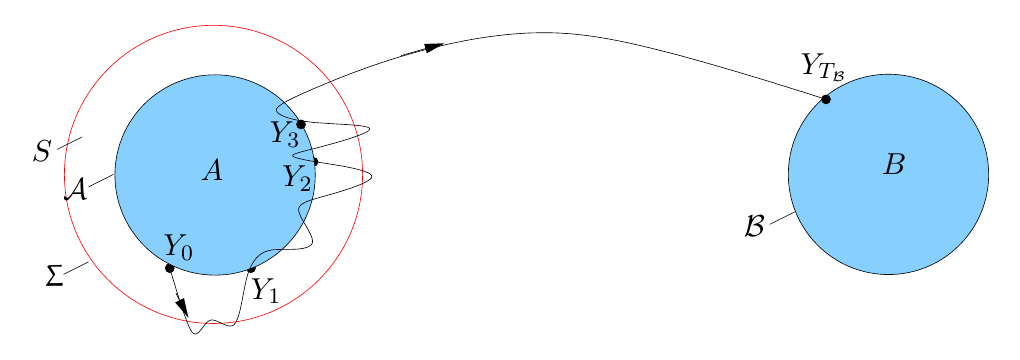

*From Baudel, Guyader, Lelièvre, 2023. Here $\mathcal A = \partial A$ and $\mathcal B = \partial B$.*

For the overdamped Langevin dynamics, the hitting times of $\partial A$ form an uncountable set with no isolated points: after leaving $\partial A$ there is no well-defined "next" hitting time.
To define these segments properly, we fix a (theoretically arbitrary) surface $\Sigma$ separating $A$ from $B$, and define $Y_{n+1}$, to be first entry point into $A \cup B$ *after a visit to $\Sigma$*.

By the strong Markov property, the sequence $(Y_n)$ forms a Markov chain on $\partial A\cup \partial B$. A step $Y_n \to Y_{n+1}$ with $Y_{n+1} \in A$ corresponds to a **loop**, and a step with $Y_n\in\partial A$ and $Y_{n+1}\in\partial B$ corresponds to the **reactive trajectory**.

Denote by $\Delta(Y_n)$ the physical time elapsed in the trajectory $Y_{n-1}\to Y_n$.
If $X_0=Y_0\in\partial A$, we can therefore express
$$
\tau_0^B = \sum_{n=1}^{T_B}\Delta(Y_n)
$$
where $T_B \in \mathbb N$ is the first index such that $Y_{T_B}\in B$, and so, taking expectations under the **reactive entry distribution** $\nu_A$,
$$
k_{A\to B} = 1/T_{A\to B},\qquad T_{A\to B} = \mathbb E_{\nu_A}\left[\sum_{n=1}^{T_B}\Delta(Y_n)\right].
$$

Since the system is metastable, the chain performs many loops before escaping, and the chain conditioned to stay in $A$ forgets $\nu_A$ and reaches a local equilibrium, **which is a QSD $\nu_Q$ on $\partial A$**. Started from $\nu_Q$, the number of steps $T_B$ is a geometric variable with parameter
$$
p = \mathbb P_{\nu_Q}(Y_1 \in B),
$$
the probability that a trajectory started from $\nu_Q$ reaches $B$ rather than coming back to $A$. Moreover $Y_{T_B} = X_{\tau_0^B}$ is independent from $T_B$.
Making the approximation $\nu_A \approx \nu_Q$ and using the law of total expectation:
$$
T_{A\to B} \approx \mathbb E_{\nu_Q}\left[\sum_{n=1}^{T_B}\Delta(Y_n)\right] = \mathbb P_{\nu_Q}(Y_1\in B)\mathbb E_{\nu_Q}\left[\Delta(Y_1)|Y_1\in B\right]
+ \mathbb P_{\nu_Q}(Y_1\in A)\left(\mathbb E_{\nu_Q}\left[\Delta(Y_1)|Y_1\in A\right] + \mathbb E_{\nu_Q}\left[\sum_{n=2}^{T_B}\Delta(Y_n)|Y_1\in A\right]\right).
$$

Since $\nu_Q$ is a QSD, the Markov property gives $\mathbb E_{\nu_Q}\left[\sum_{n=2}^{T_B}\Delta(Y_n)|Y_1\in A\right]= \mathbb E_{\nu_Q}\left[\sum_{n=1}^{T_B}\Delta(Y_n)\right]$. Rearranging the expression, we obtain the **Hill relation**
$$
T_{A\to B} \approx \frac{1-p}{p}\,\underbrace{\mathbb E_{\nu_Q}\big[\Delta(Y_1)\,\big|\,Y_1\in A\big]}_{T_{\rm loop}} + \underbrace{\mathbb E_{\nu_Q}\big[\Delta(Y_1)\,\big|\,Y_1\in B\big]}_{T_{\rm react}}
$$
The relative error of this approximation is small when the time for the chain $Y_n$ to relax to $\nu_Q$ (in number of loops) is small compared to $1/p$, the average number of loops before a transition.

**General strategy**: samples from $\nu_Q$ and $T_{\rm loop}$ can be estimated in a direct simulation phase, since loops are frequent and short if $\Sigma$ is well-chosen. $p$ and $T_{\rm react}$ are rare-event quantities, and are estimated using a splitting algorithm. The surface $\Sigma$ can be understood as a numerical parameter: the value $T_{AB}$ does not depend on it, but $p$, $T_{\rm loop}$ and the quality of the approximation $\nu_A\approx \nu_Q$ do.

### Multilevel splitting: stratified sampling in path space

We need to estimate $p = \mathbb P_{\nu_Q}(Y_1\in B)$. A step started from $Y_0 \in \partial A$ is a path that crosses $\Sigma$ and stops when it enters $A$ or $B$. Fix a **collective variable** $\xi:\mathcal X\to \mathbb R$  (or reaction coordinate), taking small values in $A$ and large values in $B$.
For simplicity, we assume $\Sigma$ is defined as a level set of $\xi$: $\Sigma = \{\xi = z_{\min}\}$.

We define the **level** $\ell(X)$ of the trajectory $Y_0\to Y_1$ as the maximum value of $\xi$ along it. For fixed levels $z_{\min} = z_0 < z_1 < \dots < z_n < z_{\max}$, where $B\subset\{\xi\geq z_{\max}\}$, we have nested events
$$
\{\ell(X) > z_1\} \supset \{\ell(X) > z_2\} \supset \dots \supset \{\ell(X) > z_n\} \supset \{Y_1 \in B\}.
$$
To reach $B$, a path must successively cross every intermediate level.

For nested events $E_1 \subset E_0$, we always have $\mathbb P(E_1) = \mathbb P(E_0\cap E_1) = \mathbb P(E_1|E_0)\mathbb P(E_0)$. This is the identity behind **stratified sampling**, which is useful to estimate the probability of any rare event $E_1$ if we know how to estimate the probabilities of $E_1|E_0$ and $E_0$.

Applying this idea recursively to our chain, we may write
$$
p = \mathbb P_{\nu_Q}\big(Y_1 \in B \,\big|\, \ell(X) > z_n\big) \mathbb P_{\nu_Q}\big(\ell(X) > z_n\,\big|\,\ell(X) > z_{n-1}\big)\dots P_{\nu_Q}\big(\ell(X) > z_1\,\big|\,\ell(X) > z_{0}\big)\mathbb P_{\nu_Q}\big(\ell(X) > z_0\big),
$$
where $\mathbb P_{\nu_Q}\big(\ell(X) > z_0\big) =1$ since any trajectory $Y_0\to Y_1$ crosses $\Sigma$ by definition.

The point is that, for well-chosen levels, the conditional probabilities $P_{\nu_Q}\big(\ell(X) > z_k\,\big|\,\ell(X) > z_{k-1}\big)$ are not small, and can therefore be approximated with relatively few trajectories.

This gives the following algorithm.

- Sample $N$ independent $Y_0\to Y_1$ trajectories (replicas) starting from $\nu_Q$
- At iteration $k$, the fraction of replicas whose level reaches above $z_{k}$ is used as an estimator of $\mathbb P_{\nu_Q}\big(\ell(X) > z_k\,\big|\,\ell(X) > z_{k-1}\big)$
- To perform iteration $k+1$, each replica below $z_{k}$ is replaced by a copy of a random surviving replica, **up to its first crossing of $\{\xi = z_{k}\}$**, and extended into a $Y_0\to Y_1$ trajectory using independent noise

By the Markov property, a path continued from its first crossing of $z_{k}$ has the law of a $Y_0\to Y_1$ trajectory conditioned on $\{\ell(X) > z_{k}\}$. The replicas sampled at iteration $k$ are therefore correlated but unbiased, and the product of the survival fractions is an unbiased estimator of $p$.

At the final iteration, replicas which reached $B$ are samples of $Y_0\to Y_1$ trajectories conditioned on $Y_1\in B$, i.e. **reactive trajectories**. They can be used to estimate $T_{\rm reac}$, the reactive entry distribution in $B$ and the reaction pathway distribution.

The difficulty lies in the choice of the levels: one can show the variance of the estimator is minimized when all conditional crossing probabilities are equal.

### Adaptive multilevel splitting (AMS)

AMS sets random levels from the replicas themselves: the next level $Z_k$ is defined as the $m$-th smallest level among the current replica population, where $m$ is a parameter. Every replica with level $\le Z_k$ is killed. There are $M_k\geq m$ of them, strictly more whenever several replicas share the same level (this can happen if replicas share the trajectory segment where their maximum level is reached). Each $\mathbb P_{\nu_Q}\big(\ell(X) > Z_k\,\big|\,\ell(X) > Z_{k-1}\big)$ is then estimated by $1 - M_k/N$.

Although the levels are random, the estimator
$$
\hat p = \prod_k \Big(1 - \frac{M_k}{N}\Big)\times\frac{N_B}{N},
$$
where $N_B$ is the number of replicas reaching $B$ in the final iteration, is **unbiased** for any choice of $\xi$, $N$ and $m$. Like in multilevel splitting, replicas which reach $B$ are correlated but unbiased reactive paths.

### The full AMS algorithm to compute reaction rates

- **A) Loop statistics.** First, we sample $Y_0\to Y_1$ trajectories, conditioned on $Y_1\in A$ with $Y_0\sim\nu_Q$.
    - **A1)** Starting from an arbitrary $Y_0\in \partial A$, sample paths $(Y_n)_{0\leq n\leq L}$ of the $A\cup B\to\Sigma\to A\cup B$ chain, rejecting those for which $T_B \leq L$.
    - **A2)** Estimate within each path, for some $0\leq n_{\rm corr}< L$,
    $$
      \overline T_{\rm loop} = \frac1{L-n_{\rm corr}}\sum_{n=n_{\rm corr}+1}^{L}\Delta(Y_n),
    $$
    and average this estimate over $N_{\rm loop}\geq 1$ independent paths (simulated in parallel).
    - **A3)** Record any $Y_n$ from **A1)** with $n\geq n_{\rm corr}$, as approximate samples of $\nu_Q$. Set $k=1$.
- **B) Initialization.** Draw $N$ samples from $\nu_Q$ simulated in step **A)**, and simulate $N$ independent $Y_0\to Y_1$ trajectories (in parallel).
- **C) Splitting and branching.** Let $Z_k$ be the $m$-th smallest level $\ell(X)$ among the current $N$ replicas, and $M_k\geq m$ the number of replicas with level $\leq Z_k$. Stop if $Z_k \geq z_{\rm max}$ or $M_k=N$.
  - **C1)** Kill the $M_k$ replicas with level $\leq Z_k$
  - **C2)** Replace these $M_k$ replicas by copies of randomly sampled survivors up to their first crossing of $Z_k$, and extend them to $Y_1$ with independent noise (in parallel). Start again from **C)** with $k\leftarrow k+1$.

$N_B$ is the number of replicas such that $Y_1\in B$ at the final iteration (in particular if $M_k=N$ at any iteration, then $N_B = 0$).
Compute $\hat p$ using the formula above (with the product over the iterations $k$ which reached **C1)**), and reactive quantities with empirical averages, e.g.
$$
\overline T_{\rm react} = \frac1{N_B} \sum_{Y\in S} \Delta(Y_1),\qquad \overline\nu_B = \frac1{N_B}\sum_{Y\in S}\delta_{Y_1},
$$
where $S$ is the set of replicas such that $Y_1\in B$ in the final iteration.

Finally, estimate the reaction rate using the Hill relation
$$
\hat k_{AB} = \left(\frac{1-\hat p}{\hat p}\,\overline T_{\rm loop} + \overline T_{\rm react}\right)^{-1}.
$$

As paths sampled within one AMS simulation are correlated, naive empirical variance estimators are not valid.
Error bars on $\hat k_{AB}$ can be obtained simply by running many independent AMS simulations.

Use the cell below to look at the code, and try to recognize steps **A)**, **B)**, **C)**, and the Hill relation.

In [ ]:
show_source(ams_simulation)

### Design parameters in adaptive multilevel splitting

As for parallel replica, a number of parameters enter into the design of AMS:

  - **the collective variable** $\xi$: this is the parameter defining the geometry of the level sets
    - `x`: the horizontal coordinate, $\xi(x, y) = x$.
    - `twisted`: another linear CV at a $-45°$ angle: $\xi(x, y) = (x - y)/\sqrt 2$.
    - `committor`: the committor function $q(x) = \mathbb P_x(\tau_B < \tau_A)$, precomputed by solving a PDE in FreeFEM++.

  - **the position of $\Sigma$**, `zmin`
    - The `low`, `medium` and `high` settings define $\Sigma$ so that the average committor $q$ over $\Sigma$ (with respect to the Gibbs measure $\mu$) is $0.005$, $0.02$ and $0.1$, respectively, for any of the above collective variables.
    - Any number will be treated as your choice of $z_{\min}$.

  - **the AMS stopping level** `zmax` in step **C)**
    - `B`: $z_{\max} = \min_B \xi$, so AMS stops when all replicas are in $A$ or all replicas are in $B$.
    - The `low`, `medium` and `high` settings place the level set $\{\xi = z_{\max}\}$ so that the Gibbs-average committor is $0.9$, $0.98$ and $0.995$ respectively.
    - Any number $z_{\max}\leq\min_B\xi$ will be treated as your choice of $z_{\max}$.

  - **loop sampling parameters**:
    - `N_loop`: the number of sample paths in step **A)**
    - `n_corr`,`L`: the burn-in parameter and path length
  
  - **initial distribution**: the distribution of $Y_0$ in step **A)**
    - `gibbs`: the Gibbs measure restricted to $A$ (this is not a measure on $\partial A$ !)
    - `dirac`: $Y_0$ is a fixed reference point on $\partial A$

  - **N**, the number of replicas, and **m**, the minimal number of replicas killed at each iteration of **C)**.

We declare an AMS design like so:
```julia
AMSDesign(
    cv        = "x",
    zmin      = "medium",
    zmax      = "B",
    N_loop    = 100,
    L         = 10,
    n_corr    = 1,
    loop_init = "gibbs",
    N         = 100,
    m         = 1,
)
```

### Movie

The following cell makes an animation of a small AMS simulation, step by step: the initialization **B)** (starting from samples of $\nu_Q$ from the loop phase **A)**, not shown), every iteration of **C)**, and the result.

**Warning**: this may take a few minutes to render depending on your machine, so use sparingly. I recommend keeping the number of replicas to $N=10$ in this animation.

In [ ]:
anim_ams = animate_algorithm(AMSDesign(cv = "x",zmin = "low",m = 1, N=10))

In [ ]:
cp(anim_ams.filename, "plots/ams_animation.gif", force = true)

### Surfaces
The following cell shows the available surfaces $\Sigma$, for both collective variables.

In [ ]:
show_levels()

### Cost versus variance leaderboard

AMS is (almost, see questions) unbiased, so the quality of a design is assessed by the **variance** of $\hat k_{AB}$ for a given simulation cost. We run $M$ independent AMS simulations and record, for each design, the relative variance of $\hat k_{AB}$ for a single simulation, against the cost of a single simulation.

As before, one unit of cost is one force evaluation, and the cost is the total number of force evaluations of a simulation.

Each legend entry reads `cv | zmin | zmax | N_loop | L | n_corr | loop_init | N | m`.

In [ ]:
design = AMSDesign(cv = "twisted", zmin = "low", N = 100, m = 10, L=2,n_corr=1)
result = run_experiment(design; M = 500)
leaderboard("ams")

You can reset the leaderboard using the following cell

In [ ]:
clear_leaderboard("ams")

### Reaction rates, pathways and entry distributions

With the following cell, you can check the estimated reaction rate and pathway probabilities, and plot the reactive entry distributions from $M$ independent AMS simulations. The error bars use the spread between the $M$ simulations.

In [ ]:
setup = AMSDesign(cv = "committor", zmin = "low", loop_init="dirac", N_loop=100, N = 100, m = 10, n_corr=0, L=1)
result = run_experiment(setup; M = 500)
k, se_k = hill_rate(result)

p, se_p = top_fraction(result)

println("k_AB = ", round(k; sigdigits = 3), " ± ", round(2se_k; sigdigits = 2), "   (reference ", round(reference().k_AB; sigdigits = 3), " ± ", round(2reference().k_AB_se; sigdigits = 2), ")") # ± 2 standard errors
println("P(top pathway) = ", round(p; digits = 3), " ± ", round(2se_p; sigdigits = 2), "   (reference ", round(reference().p_top; digits = 3), " ± ", round(2reference().p_top_se; sigdigits = 2), ")")

entry_polar(result)

## Questions for you

1. How do the variance and the computational cost depend on $m$, at fixed $N$ ? Compare $m = 1$, $m = N/10$ and $m = N/2$. What plays the role of the number of replicas in parallel replica ?
2. Take `loop_init = "dirac"`, `L = 1` and `n_corr = 0`: every replica starts either from the same point $Y_0$ of $\partial A$, or from the first entrance $Y_1$ into $A$ after it. AMS is unbiased for any initial distribution: is $\hat k_{AB}$ still correct ? What about the pathway probability and the entry distribution ? Compare `zmin = "medium"` and `zmin = "low"`: how does the influence of the starting point depend on $\Sigma$ ? How large should `n_corr` be ? Can the bias be completely removed ?
3. Take `zmin = "low"`, `n_corr = 0` and `L = 1`, then `L = 50`. Is there a bias, or only more variance ? What changes when $\Sigma$ is placed `high` ? Which approximation gets worse or better in step **A)** ?
4. Compare `cv = "x"`, `cv = "twisted"` and `cv = "committor"` at the same $N$, and compare the bias, the variance and the cost.
5. Try to find the best design in terms of efficiency: relative variance times total cost.
6. Compare `zmax = "B"`, `"high"`, `"medium"` and `"low"`. How do the variance and the cost change ?
7. The `committor` CV is not computable in high-dimensional systems. How would you design a good CV for AMS in practice ?

Question 7. is again an active research problem.

## Food for discussion

1. Which design choices introduced a **bias**, and which ones changed the **cost** ?
2. What are the tradeoffs of using parallel replica versus AMS ?
3. All of this was for equilibrium overdamped Langevin dynamics. Would this still work for underdamped equilibrium dynamics ? What about nonequilibrium dynamics ?
4. What are the hidden design choices in your favorite numerical methods, and are some of them implicit ?